# Access OceanSODA-ETHZ

[Explore re-projected dataset in the Med cube](https://sunnydean.github.io/ocean_cubes_vis/?cube=https%3A%2F%2Fs3.waw4-1.cloudferro.com%2FEarthCODE%2FOSCAssets%2Fmed_cubes%2Focean-med-monthly-cube.zarr&variable=ph_total)

This database contains the two Ocean-Soda datasets - v1 and v2, which are different products on different temporal scales and grids.

1. ocean-soda.zarr - a global monthly gridded dataset of the surface ocean carbonate system for seasonal to decadal studies of ocean acidification. The result of ocean soda v1.
2. OceanSODA_ETHZv2.r2026.GCB-fgco2-1982_2025-pyramid.zarr - which is a geozarr of a global 8day gridded dataset of the surface ocean carbonate system . The result of ocean soda v2.
3. OceanSoda v2 (2025) an older version of the above dataset.

    * Original Data Source: https://doi.org/10.25921/m5wx-ja34
    * Reference:  https://doi.org/10.25921/m5wx-ja34
    * OSC entry: https://opensciencedata.esa.int/products/ocean-soda-ethz/collection
    * License: CC-BY-NC-SA-4.0

## OceanSoda v2

In [2]:
import pandas as pd
import xarray as xr

zarr_href = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/OceanSODA_ETHZv2.r2026.GCB-fgco2-1982_2025-pyramid.zarr'

In [3]:
ds_v2 = xr.open_zarr(zarr_href, group='0') # read the first group, this is the highest resolution available data
ds_v2

<xarray.Dataset> Size: 50GB
Dimensions:      (time: 2024, lat: 720, lon: 1440, region: 4)
Coordinates:
  * time         (time) datetime64[ns] 16kB 1982-01-05 1982-01-13 ... 2025-12-29
  * lat          (lat) float64 6kB 89.88 89.62 89.38 ... -89.38 -89.62 -89.88
  * lon          (lon) float64 12kB -179.9 -179.6 -179.4 ... 179.4 179.6 179.9
  * region       (region) object 32B 'global' 'north' 'tropics' 'south'
    spatial_ref  int64 8B ...
Data variables:
    alpha        (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    area         (lat, lon) float32 4MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    fco2atm      (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    fgco2        (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    kw           (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    mask_sfc     (lat, lon) bool 1MB dask.array<chunksize=(512, 512), meta=np.ndarray>
    sfco2        (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
    tos          (time, lat, lon) float32 8GB dask.array<chunksize=(1, 512, 512), meta=np.ndarray>
Attributes:
    spatial:dimensions:      ['lat', 'lon']
    spatial:bbox:            [-180.0, -90.0, 180.0, 90.0]
    spatial:transform_type:  affine
    spatial:transform:       [0.25, 0.0, -180.0, 0.0, -0.25, 90.0]
    spatial:shape:           [720, 1440]
    spatial:registration:    pixel
    proj:code:               EPSG:4326
    proj:wkt2:               GEOGCRS["WGS 84",ENSEMBLE["World Geodetic System...
    zarr_conventions:        [{'uuid': '689b58e2-cf7b-45e0-9fff-9cfc0883d6b4'...

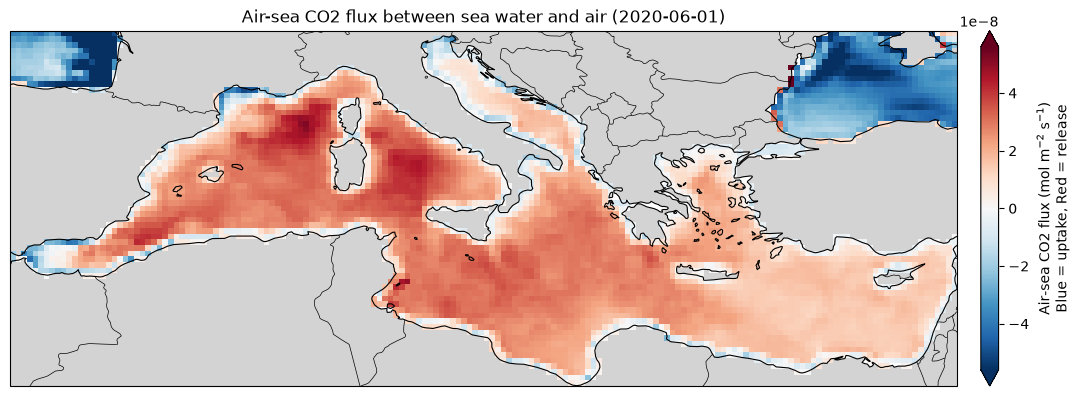

In [4]:
import cartopy.crs as ccrs
import cartopy.feature as cfeature

# Choose date
date = "2020-06-01"

# Select the air-sea CO2 flux for that date
pp = ds_v2["fgco2"].sel(
    lon=slice(-6.062, 36.06),
    lat=slice(45.98, 30.27),
)
pp = pp.sel(time=date, drop=True, method="nearest")

# use the xarray plotting interface to create a map
img = pp.plot.imshow(
    subplot_kws={"projection": ccrs.PlateCarree()},
    transform=ccrs.PlateCarree(),
    size=4,
    aspect=3,
    robust=True,
    cmap="RdBu_r",
    cbar_kwargs={"label": "Air-sea CO2 flux (mol m$^{-2}$ s$^{-1}$)\nBlue = uptake, Red = release", "pad": 0.02},
)

fig, ax = img.figure, img.axes

ax.add_feature(cfeature.LAND, facecolor="lightgray")
ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
ax.add_feature(cfeature.BORDERS, linewidth=0.5)

ax.set_title(f"Air-sea CO2 flux between sea water and air ({date})")

fig.tight_layout()

Text(0.01, 1.02, '∆$f$CO$_2$ (sea - air) over Central America showing high variability gap winds')

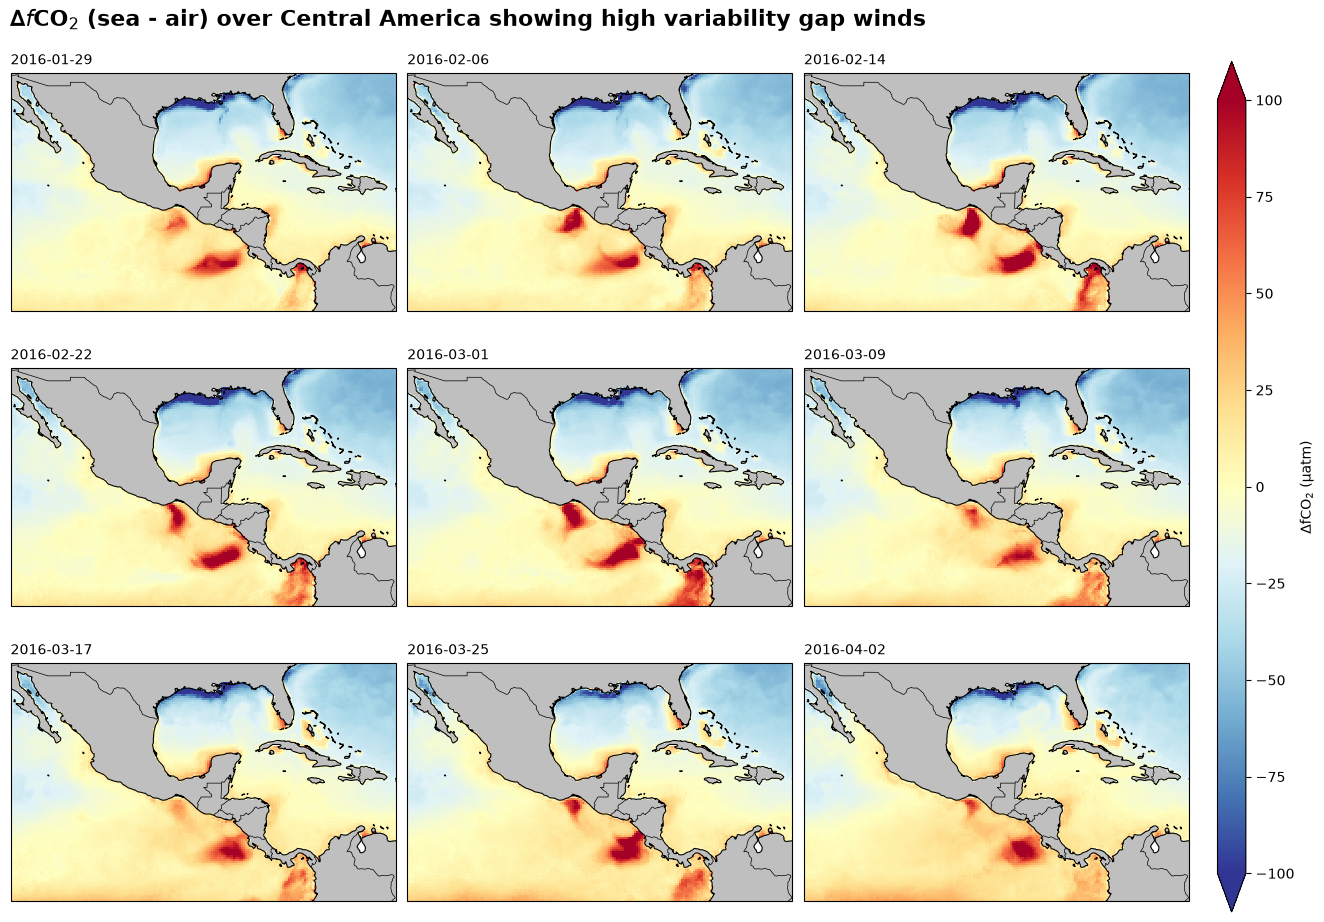

In [5]:
# calculate delta fco2 (sea - air)
dfco2 = ds_v2['sfco2'] - ds_v2['fco2atm']

# select a subset of the data for plotting (time series of maps)
da = dfco2.sel(
    lon=slice(-115.75, -67.28),
    lat=slice(33, 3),
    time=slice("2016-01-28", "2016-04-03"),
)

# plot using xarray's facet grid plotting interface
facet_grid = da.plot.imshow(
    subplot_kws={"projection": ccrs.PlateCarree()},
    transform=ccrs.PlateCarree(),
    aspect=1.5,
    size=3,
    col="time",
    col_wrap=3,
    vmin=-100, vmax=100,
    cmap="RdYlBu_r",
    cbar_kwargs={"label": "∆fCO$_2$ (µatm)", "pad": 0.02, "aspect": 30},
)


# fetch the figure and axes from the facet grid object
fig, axs = facet_grid.fig, facet_grid.axs.flatten()

# add basemap features to each subplot
for ax in axs:
    ax.add_feature(cfeature.LAND, facecolor="0.75")
    ax.add_feature(cfeature.COASTLINE, linewidth=0.8)
    ax.add_feature(cfeature.BORDERS, linewidth=0.5)

# adjusting titles
facet_grid.set_titles(template="", loc="center")
facet_grid.set_titles(template="{value}", loc="left")

fig.suptitle(
    "∆$f$CO$_2$ (sea - air) over Central America showing high variability gap winds",
    fontsize=16,
    x=0.01,
    y=1.02,
    ha="left",
    weight="bold",
)

## OceanSODA v1

OceanSODA v1 also includes information about the ocean's pH and other marine carbonate system paramters.

Here we look at how El Nino might impact pH estimates in the Eastern Equatorial Pacific

In [6]:
data_href = 'https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/ocean-soda.zarr'

In [7]:
ds_v1 = xr.open_zarr(data_href, chunks={})
ds_v1

<xarray.Dataset> Size: 3GB
Dimensions:          (time: 516, lat: 180, lon: 360)
Coordinates:
  * time             (time) datetime64[ns] 4kB 1982-01-15 ... 2024-12-15
    year             (time) int64 4kB dask.array<chunksize=(516,), meta=np.ndarray>
  * lat              (lat) float64 1kB -89.5 -88.5 -87.5 ... 87.5 88.5 89.5
  * lon              (lon) float64 3kB -179.5 -178.5 -177.5 ... 178.5 179.5
Data variables: (12/21)
    co2              (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    co3              (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    dic              (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    dic_uncert       (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    hco3             (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    omega_ar         (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    ...               ...
    sfco2_uncert     (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    spco2            (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    spco2_uncert     (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    talk             (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    talk_uncert      (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
    temperature      (time, lat, lon) float32 134MB dask.array<chunksize=(516, 45, 45), meta=np.ndarray>
Attributes:
    contact:      gregorl@ethz.ch
    author:       Luke Gregor
    institution:  ETH Zuerich
    version:      v2025.OCADS
    date:         2025-10-09
    description:  talk and pco2 (more accurately fco2) are estimated with two...
    changelog:    v2021d: Extended from 1982-2020; Now using: OISSTv2.1 for S...
    reference:    Gregor, L. and Gruber, N.: OceanSODA-ETHZ: A global gridded...
    source:       https://doi.org/10.25921/m5wx-ja34
    product:      OSETHZ-v2025.OCADS

In [9]:
names = [
    "YR",
    "MON",
    "NINO1+2",
    "NINO1+2 ANOM",
    "NINO3",
    "NINO3 ANOM",
    "NINO4",
    "NINO4 ANOM",
    "NINO3.4",
    "NINO3.4 ANOM",
]

nino = pd.read_fwf(
    "https://www.cpc.ncep.noaa.gov/data/indices/sstoi.indices",
    skiprows=1,
    names=names,
)

# Create datetime index
nino.index = pd.to_datetime(
    dict(year=nino["YR"], month=nino["MON"], day=1)
)

# Extract Niño 3.4 anomalies
nino34 = nino["NINO3.4 ANOM"]

# Identify months with anomalies above 1.5°C
el_nino = (nino34 > 1.5).astype(int)

Text(0.0, 1.0, 'Mean pH in the equatorial Pacific Ocean (5°S - 5°N, 180°W - 100°W)')

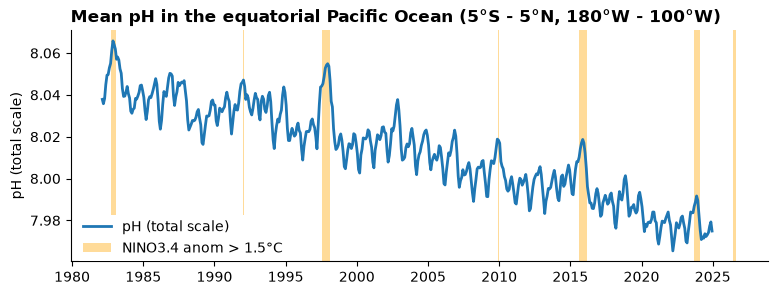

In [10]:
(line,) = (
    ds_v1.ph_total
    .sel(lat=slice(-5, 5), lon=slice(-180, -100))
    .mean(dim=["lat", "lon"])
    .plot(size=3, aspect=3, label="pH (total scale)", color="tab:blue", lw=2)
)

fig, ax = line.get_figure(), line.axes

ax.set_ylabel("pH (total scale)")
ax.set_xlabel("")

ax.spines["top"].set_visible(False)
ax.spines["right"].set_visible(False)

# highlight El Niño periods
ax.fill_between(
    el_nino.index,
    0,
    1,
    where=el_nino == 1,
    color="orange",
    alpha=0.4,
    lw=0,
    transform=ax.get_xaxis_transform(),
    label="NINO3.4 anom > 1.5°C",
)

ax.legend(loc=(0.01, 0), framealpha=1, edgecolor="none")
ax.set_title("Mean pH in the equatorial Pacific Ocean (5°S - 5°N, 180°W - 100°W)", loc="left", weight="bold")

## Visualisation

The ocean soda v2 dataset is in geozarr format. This means that the data is available at multiple resolutions and can be interactively visualised by any GeoZarr viewer by passing the dataset url. For example:
1. The viewer from the project team and the associated library (https://github.com/lukegre/geozarr-pyramid-maker/tree/main) : https://lukegre.github.io/geozarr-pyramid-maker/viewer/
2. Through open-layers: https://sunnydean.github.io/ocean_cubes_vis/?cube=https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/OceanSODA_ETHZv2.r2026.GCB-fgco2-1982_2025-pyramid.zarr&variable=sfco2
3. Through gridlook - https://gridlook.pages.dev/#https://s3.waw4-1.cloudferro.com/EarthCODE/OSCAssets/ocean-soda/OceanSODA_ETHZv2.r2026.GCB-fgco2-1982_2025-pyramid.zarr

See the visualisation section for more info.